In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sales_data = pd.read_csv("ecommerce_sales.csv")
sales_data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [5]:
total_revenue = sales_data['revenue'].sum()
print(f"Total Revenue: Rs. {total_revenue:,.2f}")

Total Revenue: Rs. 5,109,775.74


The total revenue represents the sum of revenue generated from all orders in the dataset.

In [6]:
total_orders = sales_data['order_id'].nunique()
print(f"Total Orders: {total_orders}")

Total Orders: 5000


In [7]:
unique_customers = sales_data['customer_id'].nunique()
print(f"There are {unique_customers} unique customers.")

There are 989 unique customers.


In [8]:
average_revenue_per_order = total_revenue/total_orders


In [9]:
total_quantity_sold = sales_data['quantity'].sum()


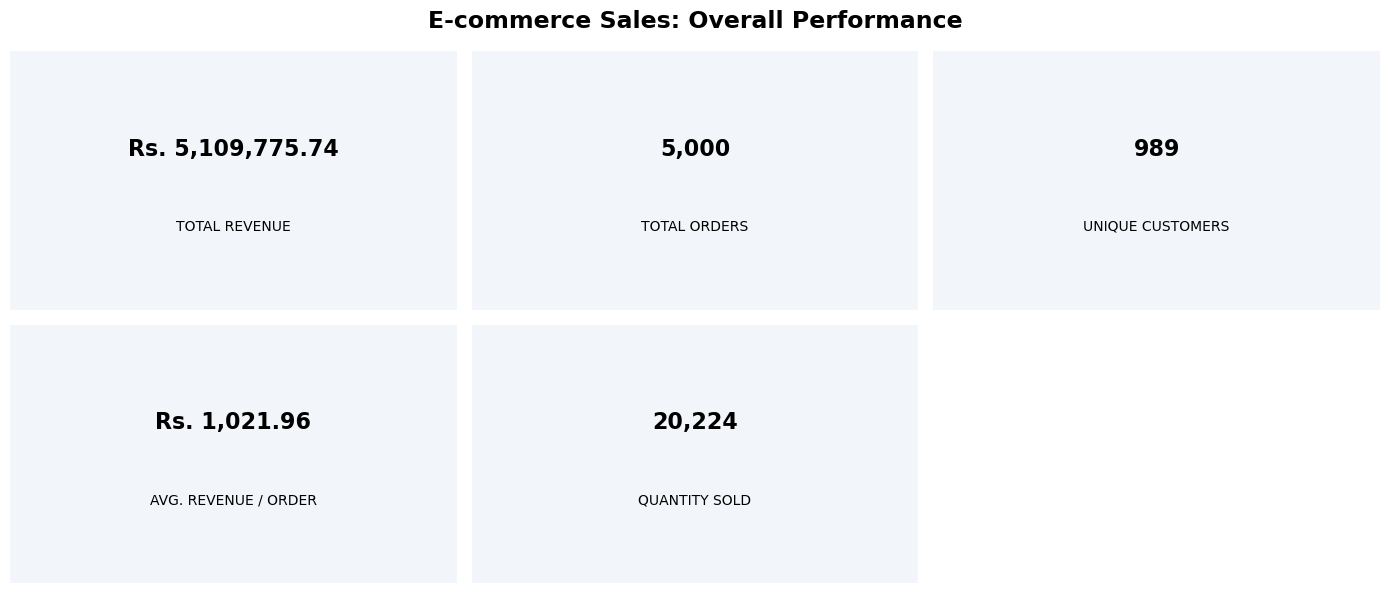

In [10]:


# Create KPI values
kpis = [
    ("TOTAL REVENUE", f"Rs. {total_revenue:,.2f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNIQUE CUSTOMERS", f"{unique_customers:,}"),
    ("AVG. REVENUE / ORDER", f"Rs. {average_revenue_per_order:,.2f}"),
    ("QUANTITY SOLD", f"{total_quantity_sold:,}")
]

fig,axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()

for i, (title, value) in enumerate(kpis):
    axes[i].set_facecolor("#F2F5F9")
    axes[i].text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=16, fontweight="bold",
        transform=axes[i].transAxes
    )
    axes[i].text(
        0.5, 0.32, title,
        ha="center", va="center",
        fontsize=10,
        transform=axes[i].transAxes
    )

    axes[i].set_xticks([])
    axes[i].set_yticks([])

    for spine in axes[i].spines.values():
        spine.set_visible(False)

# Hide the unused sixth card
axes[5].axis("off")

fig.suptitle(
    "E-commerce Sales: Overall Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


The summary of KPIs gives a brief description of the performance of the e-commerce business. The total revenue shows the income generated; total orders and unique customers represents sales activity, average revenue per order shows the income per transaction, while the total quantity sold shows the number of products sold.

### OVERALL SALES ANALYSIS

In [11]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().round(2).sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

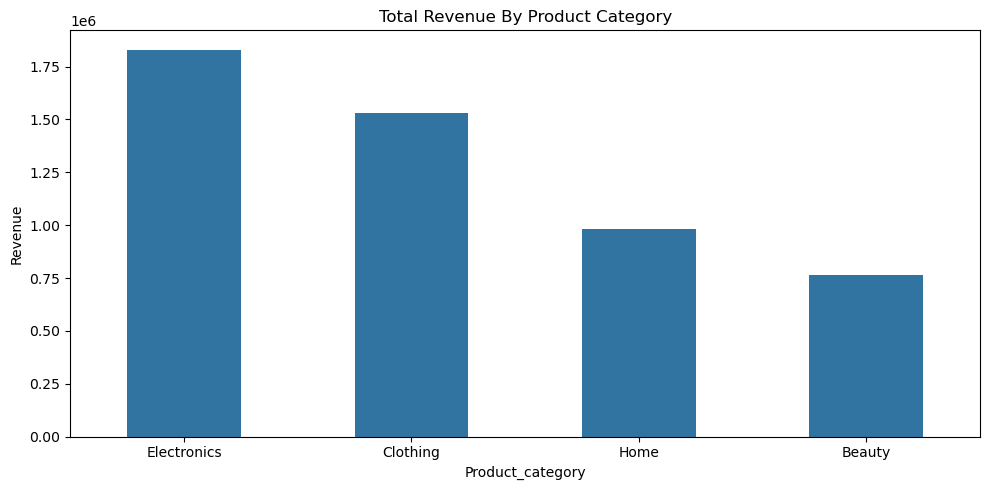

In [12]:
plt.figure(figsize=(10,5))
sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.5)
plt.title('Total Revenue By Product Category')
plt.xlabel('Product_category')
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

In [13]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

In [14]:
monthly_revenue = (
    sales_data.groupby(sales_data['order_date'].dt.month)['revenue']
    .sum()
    .sort_index()
)
monthly_revenue

order_date
1     426374.92
2     413890.24
3     425050.52
4     398715.16
5     479772.55
6     442941.58
7     440570.72
8     460874.78
9     402368.11
10    407873.12
11    410657.88
12    400686.16
Name: revenue, dtype: float64

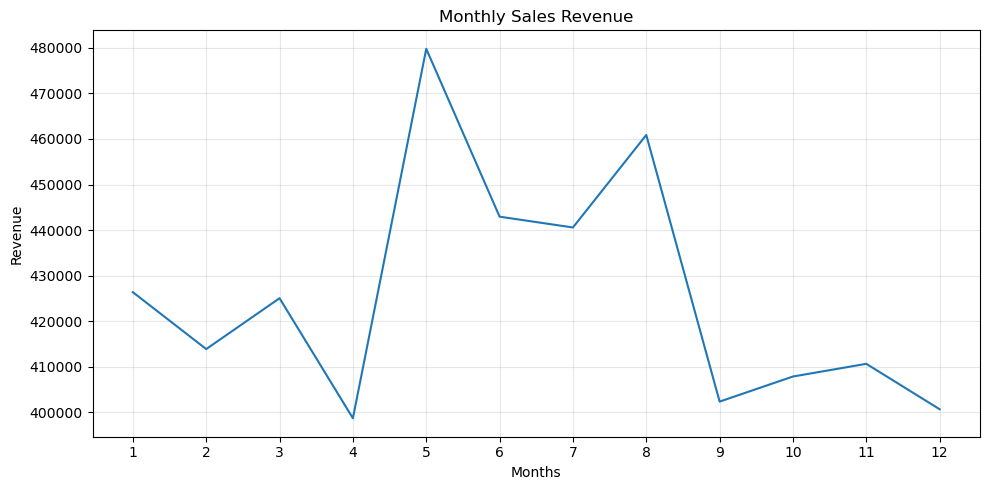

In [15]:
plt.figure(figsize=(10,5))
sns.lineplot(monthly_revenue)
plt.title("Monthly Sales Revenue")
plt.xlabel('Months')
plt.ylabel('Revenue')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

May generated the highest revenue, followed by August, while April had the lowest revenue. This shows that sales revenue varied from month to month. The business can look at what made May more successful and use those findings to improve sales during months with lower revenue.

In [16]:
Yearly_sales_revenue = sales_data.groupby(sales_data['order_date'].dt.year)['revenue'].sum().sort_values(ascending=False)
Yearly_sales_revenue

order_date
2033    408725.72
2030    387884.46
2032    386584.63
2026    386369.69
2027    386151.91
2028    376844.80
2022    371824.30
2023    365915.79
2031    365250.83
2034    363239.55
2024    363209.13
2029    359239.24
2025    349802.33
2035    238733.36
Name: revenue, dtype: float64

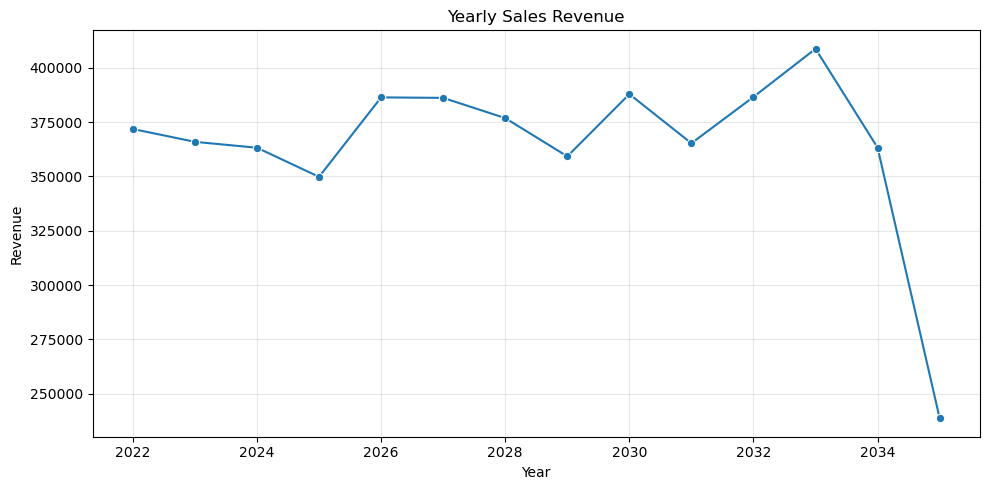

In [17]:
plt.figure(figsize=(10,5))
sns.lineplot(Yearly_sales_revenue,marker='o')
plt.title('Yearly Sales Revenue')
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Yearly sales revenue went up and down over the years instead of showing steady growth. Revenue was highest in 2033 and lowest in 2035. The drop in revenue in 2035 suggests that the business should look into possible reasons for the decline and find ways to improve sales.

In [18]:
monthly_orders = (
    sales_data.groupby(sales_data['order_date'].dt.month)['order_id']
    .nunique()
    .sort_index()
)
monthly_orders

order_date
1     434
2     395
3     434
4     420
5     434
6     420
7     434
8     434
9     399
10    403
11    390
12    403
Name: order_id, dtype: int64

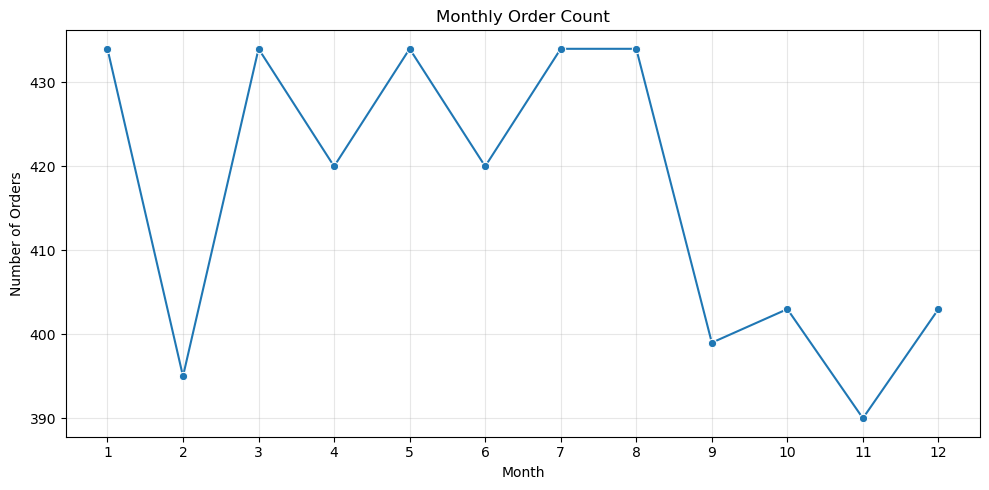

In [19]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_orders.index, y=monthly_orders.values, marker='o')
plt.title('Monthly Order Count')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


January, March, May, July, and August had the highest number of orders, with 434 orders each. November had the fewest orders, with 390. Overall, the number of orders was fairly stable throughout the year, although November had slightly lower sales activity than the other months.

In [20]:
# plt.figure(figsize=(10,5))
# plt.title('Monthly Order Count')
# sns.barplot(x=monthly_orders.index,y=monthly_orders.values)
# plt.xlabel('Months')
# plt.ylabel('Number of orders')
# plt.tight_layout()
# plt.show()

### PRODUCT CATEGORY ANALYSIS

#### Which product category generates highest revenue?

In [21]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

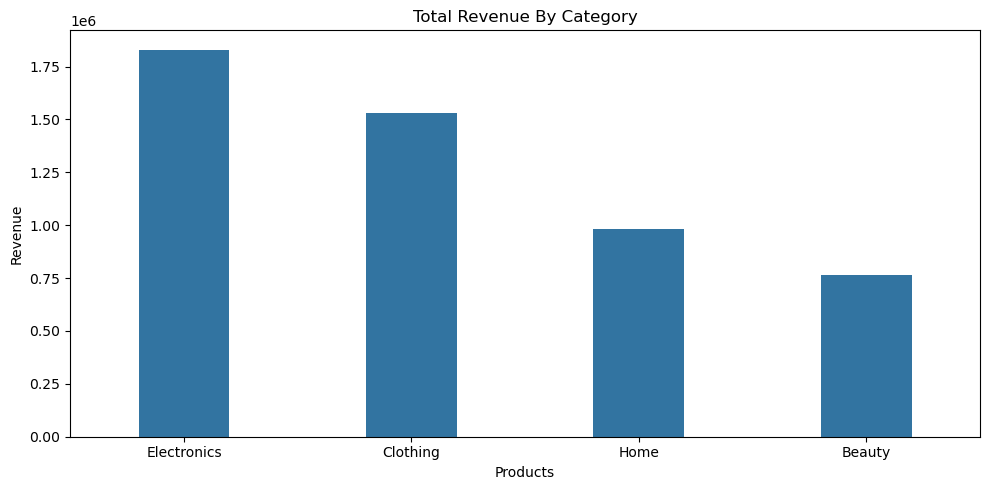

In [22]:
plt.figure(figsize=(10,5))
sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.4)
plt.title('Total Revenue By Category')
plt.xlabel('Products')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

#### Which category sells the most quantity?

In [23]:
quantity_by_category = sales_data.groupby('product_category')['quantity'].sum().sort_values(ascending=False)
quantity_by_category

product_category
Electronics    7109
Clothing       6171
Home           3949
Beauty         2995
Name: quantity, dtype: int64

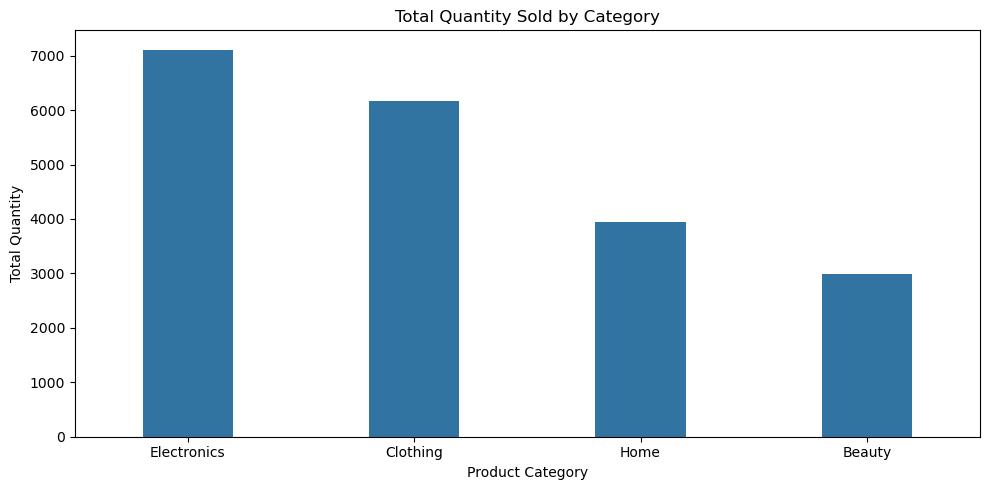

In [107]:
plt.figure(figsize=(10,5))
sns.barplot(x=quantity_by_category.index,y=quantity_by_category.values,width=0.4)
plt.title("Total Quantity Sold by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()

#### Which category has the highest average customer rating?

In [105]:
rating_by_category=sales_data.groupby('product_category')['customer_rating'].mean().round()
rating_by_category

product_category
Beauty         3.0
Clothing       3.0
Electronics    3.0
Home           3.0
Name: customer_rating, dtype: float64

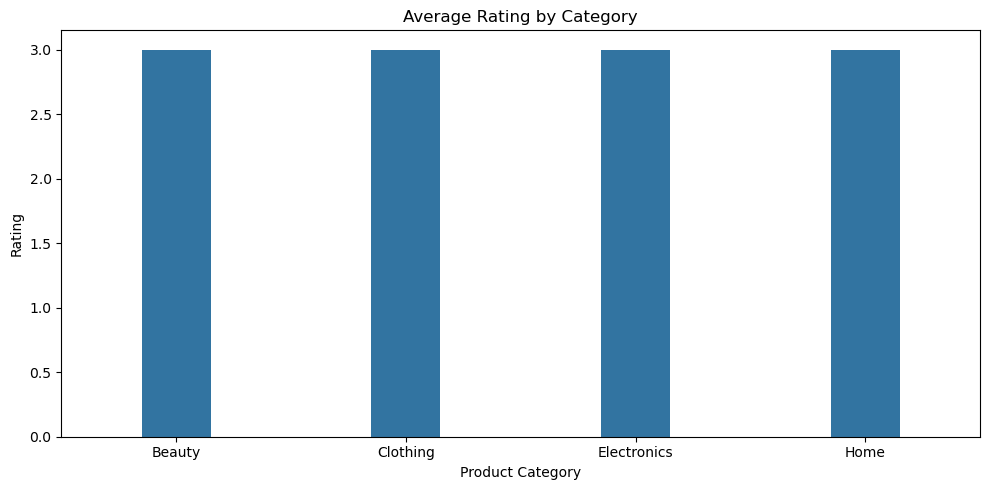

In [106]:
plt.figure(figsize=(10,5))
sns.barplot(x=rating_by_category.index,y=rating_by_category.values,width=0.3)
plt.title('Average Rating by Category')
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()

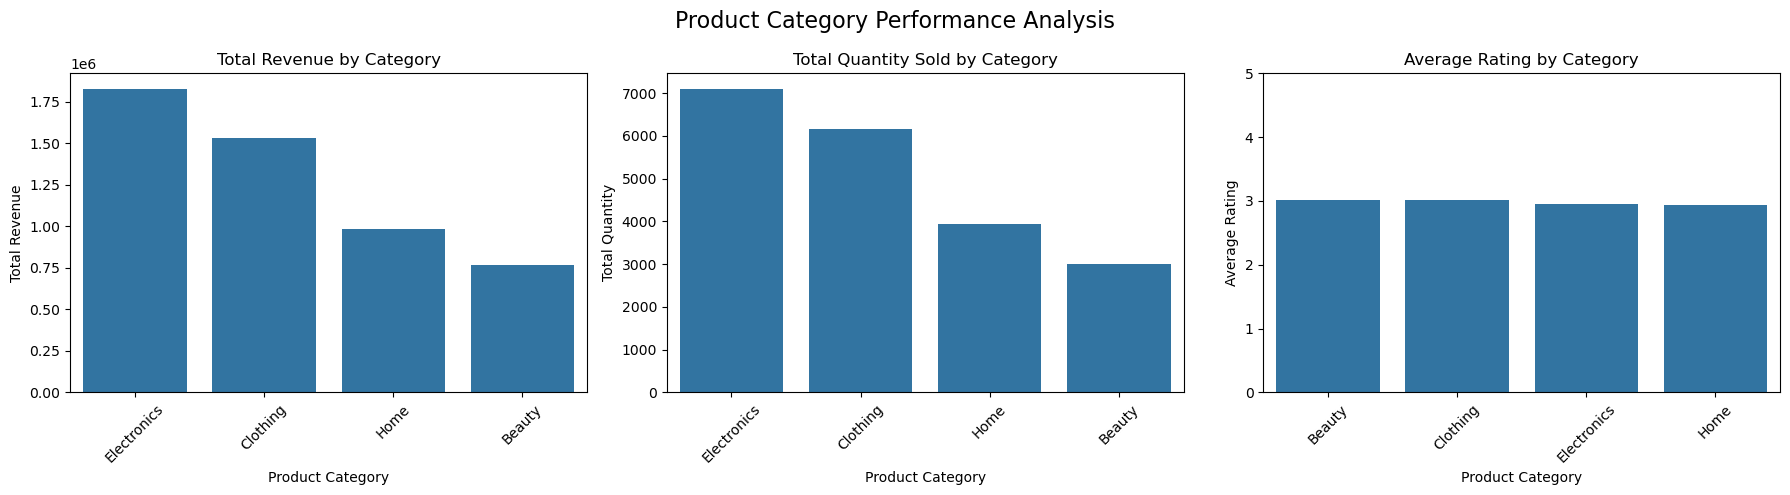

### Regional Sales Analysis

#### Which region generates the highest revenue?

In [28]:
region_wise_revenue = sales_data.groupby('region')['revenue'].sum().sort_values(ascending=False)
# print(f"Revenue By Region \n\n{region_wise_revenue}\n")

region_wise_orders = sales_data.groupby('region')['order_id'].nunique()
# print(f"Order count By Region \n\n {region_wise_orders}\n")

region_wise_rating = sales_data.groupby('region')['customer_rating'].mean()
# print(f"Rating By Region \n\n{region_wise_rating}\n")

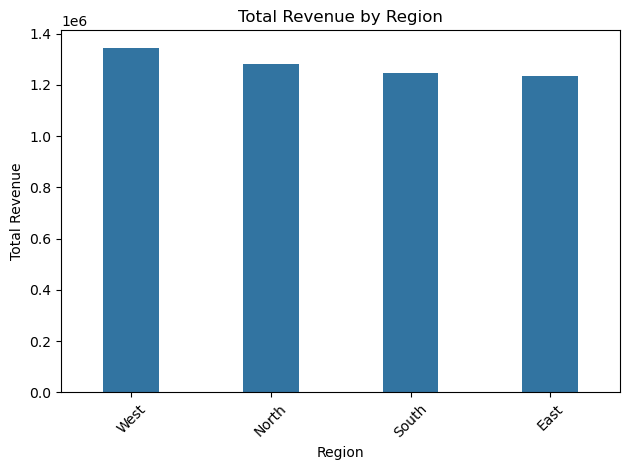

In [109]:
sns.barplot(
    x=region_wise_revenue.index,
    y=region_wise_revenue.values,
    width=0.4
)

plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

The West region generated the highest revenue of 1,345,582.16, followed by the North region. The East region recorded the lowest revenue at 1,236,044.23. Overall, revenue was relatively balanced across all four regions, but the West region contributed the most to total sales.

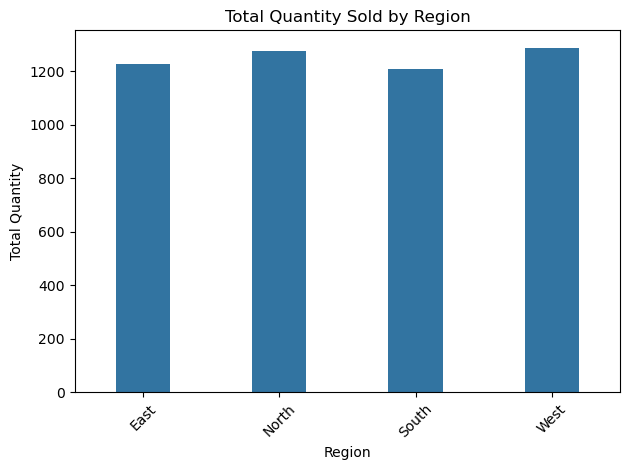

In [111]:
sns.barplot(
    x=region_wise_orders.index,
    y=region_wise_orders.values,
    width=0.4
)

plt.title('Total Quantity Sold by Region')
plt.xlabel('Region')
plt.ylabel('Total Quantity')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


The West region sold the highest quantity of products, followed closely by the North region. The South region recorded the lowest quantity sold, while the East region performed slightly better. This indicates that the West region performed strongly in terms of both revenue and sales volume.

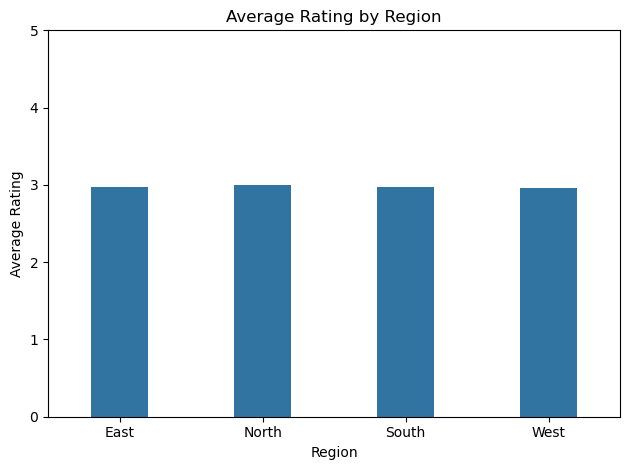

In [116]:
sns.barplot(
    x=region_wise_rating.index,
    y=region_wise_rating.values,
    width=0.4
)

plt.title('Average Rating by Region')
plt.xlabel('Region')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

The North region received the highest average customer rating of approximately 2.99, while the West region had the lowest at approximately 2.96. The differences are very small, and all regions have ratings close to 3 out of 5. This suggests that customer feedback is fairly consistent across regions, but customer satisfaction could be improved.

### Conclusion
The West region was the strongest performer in terms of revenue and quantity sold, while the North region achieved the highest customer rating. Although sales performance was relatively balanced across all regions, average customer ratings remained around 3 out of 5. The business should focus on maintaining strong sales in the West while improving customer satisfaction across all regions through better product quality, delivery services, and customer support.

### Customer Analysis

In [94]:
revenue_by_customers = sales_data.groupby('customer_id')['revenue'].sum().round(2).sort_values(ascending=False).head(10)
# print(revenue_by_customers)

orders_per_customers = sales_data.groupby('customer_id')['order_id'].nunique()
# print(orders_per_customers)

revenue_per_orders=sales_data.groupby('order_id')['revenue'].sum()
# revenue_by_orders

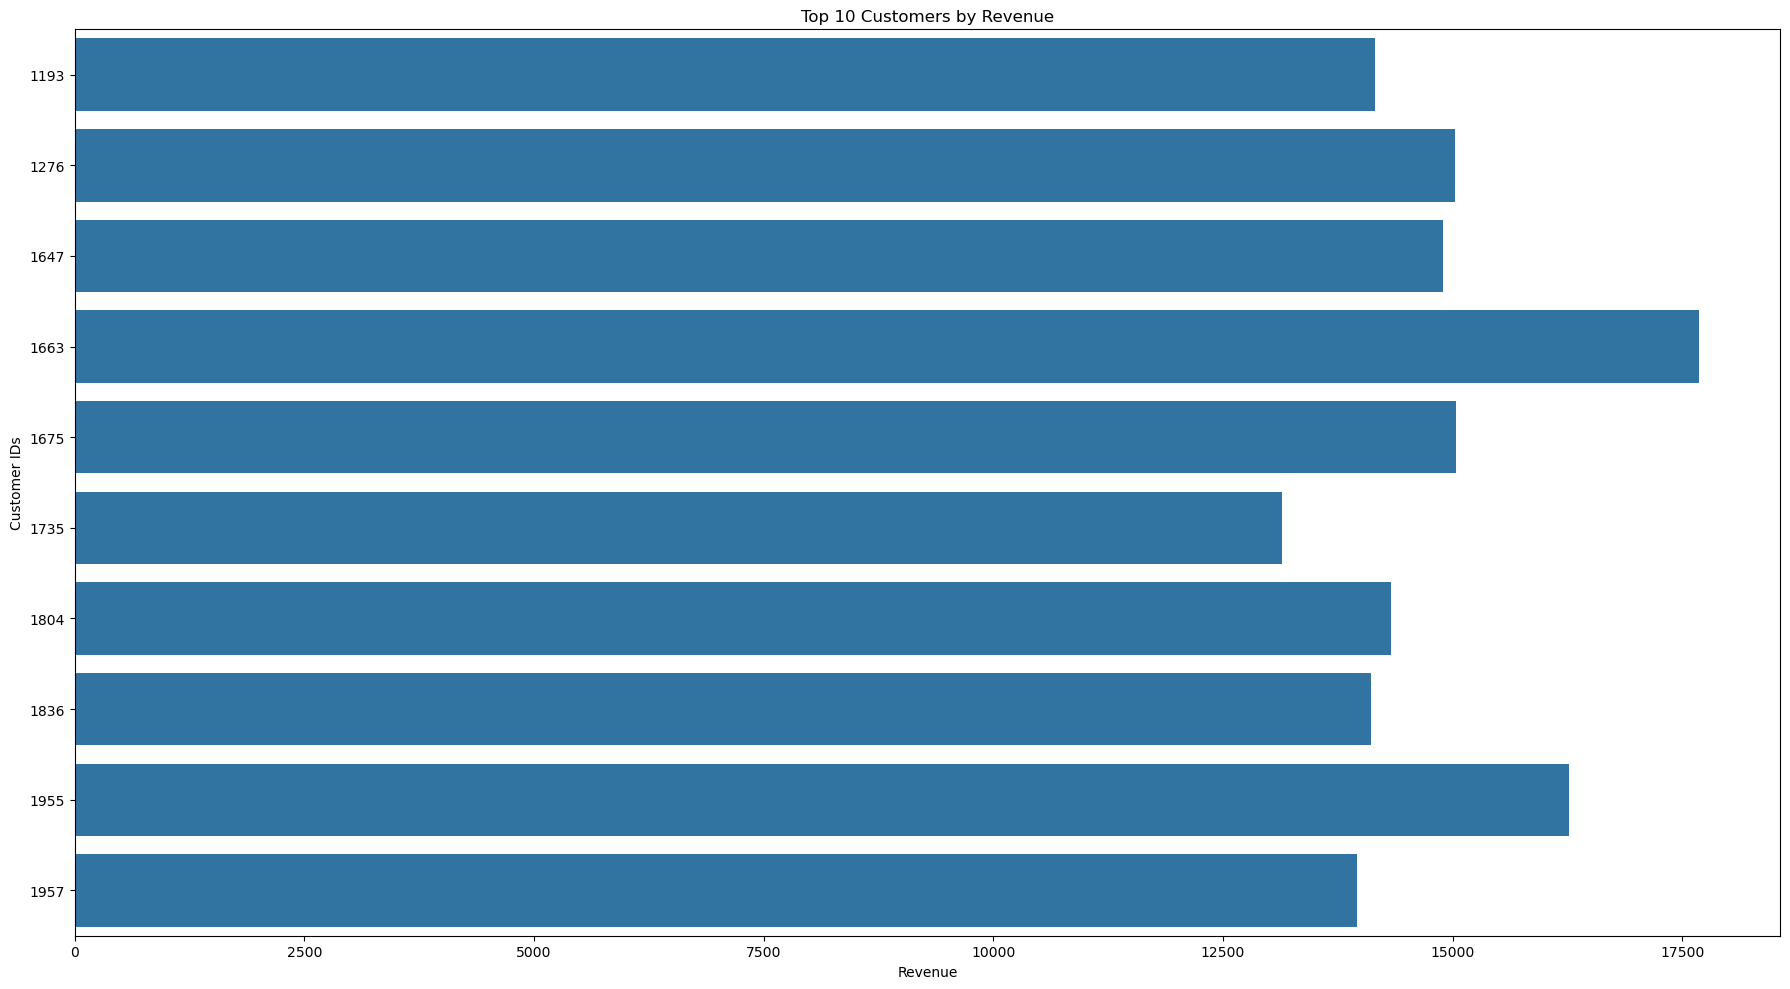

In [119]:
plt.figure(figsize=(18,10))
sns.barplot(x=revenue_by_customers.values,
            y=revenue_by_customers.index,
            orient='h')
plt.title('Top 10 Customers by Revenue')
plt.ylabel('Customer IDs')
plt.xlabel('Revenue')
plt.tight_layout()
plt.show()

The chart shows which customers bring in the most revenue for the business. These customers are valuable because they contribute a good amount to overall sales. The business should focus on keeping these customers satisfied and encouraging them to continue shopping.

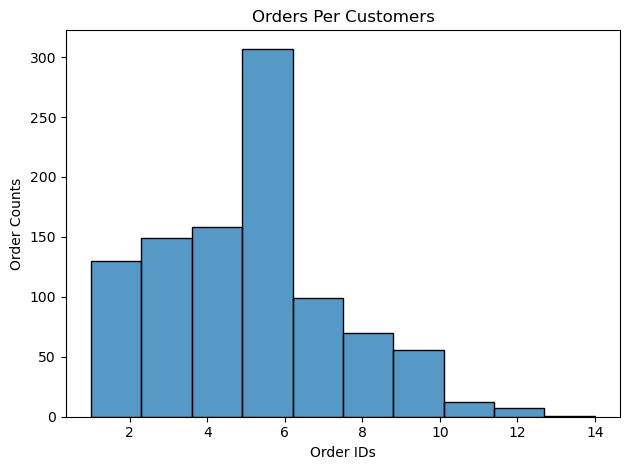

In [101]:
sns.histplot(orders_per_customers,kde=False,bins=10)
plt.title('Orders Per Customers')
plt.xlabel('Order IDs')
plt.ylabel('Order Counts')
plt.tight_layout()
plt.show()

The chart helps us understand how often customers purchase from the business. Some customers order more frequently than others, which shows that purchasing habits vary. The business could encourage customers who order less often to return and make more purchases.

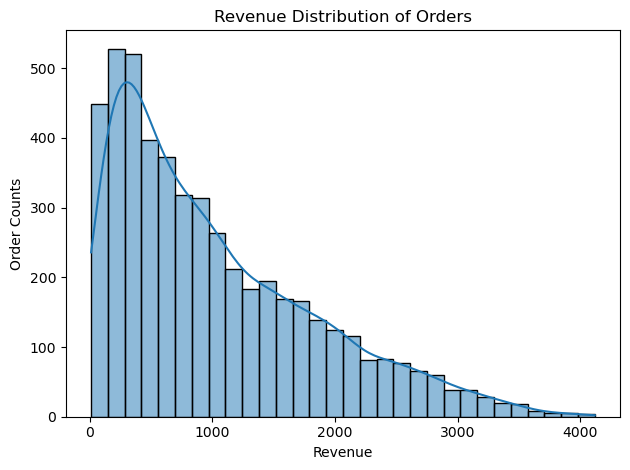

In [102]:
sns.histplot(revenue_per_orders, bins=30, kde=True)
plt.title('Revenue Distribution of Orders')
plt.xlabel('Revenue')
plt.ylabel('Order Counts')
plt.tight_layout()
plt.show()

The chart shows that most orders generate relatively low revenue, while only a few orders generate much higher revenue. This means high-value orders are less common. The business could encourage customers to purchase additional or related products to increase the amount spent per order.

#### Conclusion
Customer analysis shows that the business has customers with different purchasing patterns. Most customers place around 5–6 orders, and most individual orders generate relatively low revenue. A small number of orders contribute higher amounts, while the top customers provide valuable revenue to the business. The company could focus on customer retention, encouraging repeat purchases, and increasing the value of smaller orders to improve overall sales performance.

### Payment Method Analysis

In [123]:
order_by_payment = sales_data.groupby('payment_method')['order_id'].nunique()
order_by_payment

payment_method
COD       1774
Card      2270
Wallet     956
Name: order_id, dtype: int64

<Axes: xlabel='payment_method'>

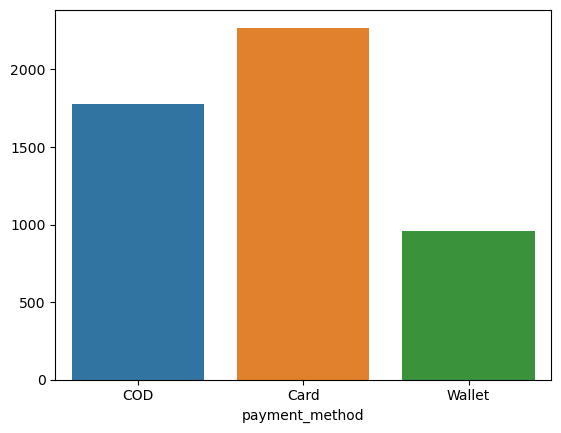

In [128]:
sns.barplot(x=order_by_payment.index,y=order_by_payment.values,hue=order_by_payment.index)

In [129]:
!git status -sb

## main...origin/main [ahead 4, behind 19]
A  .gitignore
D  .ipynb_checkpoints/ecommerce_sales_anlaysis-checkpoint.ipynb
D  .ipynb_checkpoints/sales_visualization-checkpoint.ipynb
A  README.md
AM ecommerce_sales_analysis.ipynb
D  ecommerce_sales_anlaysis.ipynb
AM ecommerce_sales_visualization.ipynb
D  netflix_data_analysis/.ipynb_checkpoints/netflix_data-checkpoint.ipynb
 D netflix_data_analysis/NetFlix.csv
AD netflix_data_analysis/README.md
MD netflix_data_analysis/netflix_data.ipynb
D  sales_visualization.ipynb
?? sales_data_csv.csv


In [131]:
pwd

'C:\\Users\\Dell\\projects\\ecommerce_sales_analysis'